# Wasserstein GAN to generate steel samples 

In [24]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import tensorflow as tf
import joblib
import numpy as np
from sklearn.model_selection import train_test_split
import xgboost as xgb
import keras.backend as K
from keras.optimizers import Adam
import random
import keras
from keras.layers import Dense
from keras.layers import Dropout
from keras.models import Sequential
from keras.src.layers import LeakyReLU, BatchNormalization, Activation
from keras.src.optimizers import Adam

<br>

## 1. Load and prepare data

In [2]:
# Read labeled_OES_data_2.csv
data = pd.read_csv("labeled_OES_data_2.csv")

# convert steel types to numbers
# Note: in our project steel types are not predefined, but will be extracted from the supplied file of data
classes_dict = {"St 48" : 0, "St 37" : 1, "St Si" : 2, "St 48-TH" : 3, "Puddelstahl" : 4}
data["steel_class"] = [classes_dict[c] for c in data["steel_class"] ]    

# make data numeric
for column in data.columns:
        for index, value in data[column].items():
            if isinstance(value, str):
                data.at[index, column] = value.replace(",", ".")
data = data.map(pd.to_numeric)
data.head()

,C,Si,Mn,P,S,Cr,Ni,Al,Cu,steel_class
0,0.104,0.806,0.890,0.031,0.044,0.013,0.047,0.006,0.168,2
1,0.262,0.219,0.525,0.021,0.040,0.035,0.051,0.002,0.145,0
2,0.235,0.239,0.729,0.028,0.042,0.015,0.050,0.004,0.167,0
3,0.116,0.848,0.737,0.023,0.038,0.053,0.070,0.006,0.172,2
4,0.195,0.321,0.570,0.033,0.057,0.023,0.075,0.007,0.281,0


## 2. Group dataset by steel types

In [3]:
element_data_grouped_by_steeltype = data.groupby("steel_class")
dfs_by_steeltype = {}

for type, group_data in element_data_grouped_by_steeltype:
    dfs_by_steeltype[type] = group_data.iloc[:, :-1]

for type in dfs_by_steeltype.keys():
    print(f"\nSteel Type {type}:")
    print(dfs_by_steeltype[type].head())


Steel Type 0:
       C     Si     Mn      P      S     Cr     Ni     Al     Cu
1  0.262  0.219  0.525  0.021  0.040  0.035  0.051  0.002  0.145
2  0.235  0.239  0.729  0.028  0.042  0.015  0.050  0.004  0.167
4  0.195  0.321  0.570  0.033  0.057  0.023  0.075  0.007  0.281
5  0.130  0.438  0.691  0.020  0.037  0.020  0.044  0.004  0.437
7  0.284  0.233  0.635  0.022  0.042  0.009  0.050  0.003  0.175

Steel Type 1:
        C     Si     Mn      P      S     Cr     Ni     Al     Cu
12  0.076  0.005  0.402  0.017  0.018  0.044  0.036  0.002  0.091
17  0.070  0.005  0.428  0.008  0.018  0.005  0.027  0.002  0.098
33  0.069  0.005  0.392  0.020  0.028  0.008  0.035  0.002  0.122
36  0.058  0.005  0.393  0.029  0.030  0.022  0.052  0.002  0.172
37  0.061  0.005  0.312  0.020  0.035  0.025  0.047  0.002  0.147

Steel Type 2:
        C     Si     Mn      P      S     Cr     Ni     Al     Cu
0   0.104  0.806  0.890  0.031  0.044  0.013  0.047  0.006  0.168
3   0.116  0.848  0.737  0.023  0.038

<br>

## 3. Create construct for WGAN

In [4]:
def build_generator(latent_space):
    generator = Sequential()
    generator.add(Dense(latent_space, input_dim=latent_space))
    generator.add(LeakyReLU(alpha=0.2))
    generator.add(BatchNormalization(momentum=0.8))
    generator.add(Dense(256))
    generator.add(LeakyReLU(alpha=0.2))
    generator.add(BatchNormalization(momentum=0.8))
    generator.add(Dense(512))
    generator.add(LeakyReLU(alpha=0.2))
    generator.add(BatchNormalization(momentum=0.8))
    generator.add(Dense(9))
    generator.add(Activation('sigmoid'))
    return generator

In [5]:
def build_critic():
    critic = Sequential()
    critic.add(Dense(9, input_dim=9))
    critic.add(Dense(512))
    critic.add(LeakyReLU(alpha=0.2))
    critic.add(Dropout(0.3))
    critic.add(Dense(256))
    critic.add(LeakyReLU(alpha=0.2))
    critic.add(Dropout(0.3))
    critic.add(Dense(128))
    critic.add(LeakyReLU(alpha=0.2))
    critic.add(Dense(1))
    return critic

In [6]:
def build_wgan(generator, critic):
    #critic.trainable = False
    wgan = Sequential()
    wgan.add(generator)
    wgan.add(critic)
    return wgan

In [7]:
def wasserstein_loss_gen(fake_output):
    return -tf.reduce_mean(fake_output)

def wasserstein_loss_critic(real_output, fake_output):
    return -(tf.reduce_mean(real_output) - tf.reduce_mean(fake_output))

In [8]:
# testing of alteration of GP
def gradient_penalty_replace(gp_lambda, critic, real, fake):
    # interpolation
    interpolation = real.copy()
    rand_epsilon_length = random.randint(0, 8)
    rand_index = random.randint(0, 8)
    epsilon = []
    while len(epsilon) < rand_epsilon_length:
        if rand_index not in epsilon:
            epsilon.append(rand_index)
        rand_index = random.randint(0, 8)

    for index in epsilon:
        interpolation[0][index] = fake[0][index]

    interpolation_tensor = tf.constant(interpolation, dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(interpolation_tensor)
        c_output = critic(interpolation_tensor)
    gradient = tape.gradient(c_output, interpolation_tensor)
    norm_grad = tf.norm(gradient, axis=1)
    return gp_lambda * tf.reduce_mean((norm_grad - 1) ** 2)

In [18]:
def gradient_penalty_mix(gp_lambda, critic, real, fake):
    # interpolation
    interpolation = real.copy()
    epsilon = random.random()
    for index in range(9):
        interpolation[0][index] = epsilon * interpolation[0][index] + (1 - epsilon) * fake[0][index]

    interpolation_tensor = tf.constant(interpolation, dtype=tf.float32)

    with tf.GradientTape() as tape:
        tape.watch(interpolation_tensor)
        c_output = critic(interpolation_tensor)
    gradient = tape.gradient(c_output, interpolation_tensor)
    norm_grad = tf.norm(gradient, axis=1)
    return gp_lambda * tf.reduce_mean((norm_grad - 1) ** 2)

<br>

## 4. Create Generator, Discriminator and WGAN

In [12]:
latent_space = 20
optimizer_critic = Adam(
        learning_rate=1e-4, 
        beta_1=0,
        beta_2=0.9
    )
optimizer_wgan = Adam(
        learning_rate=1e-4, 
        beta_1=0,
        beta_2=0.9
    )

critic_St37 = build_critic()
critic_St37.compile(optimizer=optimizer_critic, loss=wasserstein_loss_critic)

generator_St37 = build_generator(latent_space)
generator_St37.summary()

wgan_St37 = build_wgan(generator_St37, critic_St37)
wgan_St37.compile(optimizer=optimizer_wgan, loss=wasserstein_loss_gen)

C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                      │ (None, 20)                  │             420 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_3 (LeakyReLU)            │ (None, 20)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 20)                  │              80 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 256)                 │           5,376 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_4 (LeakyReLU)            │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 256)                 │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 512)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_5 (LeakyReLU)            │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 512)                 │           2,048 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_10 (Dense)                     │ (None, 9)                   │           4,617 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation (Activation)              │ (None, 9)                   │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 145,149 (566.99 KB)

 Trainable params: 143,573 (560.83 KB)

 Non-trainable params: 1,576 (6.16 KB)

In [13]:
critic_St37.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                      │ (None, 9)                   │              90 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 512)                 │           5,120 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu (LeakyReLU)              │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 256)                 │         131,328 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_1 (LeakyReLU)            │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 256)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 128)                 │          32,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ leaky_re_lu_2 (LeakyReLU)            │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_6 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 169,563 (662.36 KB)

 Trainable params: 169,563 (662.36 KB)

 Non-trainable params: 0 (0.00 B)

<br>

## 5. Train the GAN

**To make the first training more ressource friendly we chose a low number of epochs and a low batch size**

In [16]:
epochs = 3
batch_size = 64
iteration_critic = 5

X_train_St37 = dfs_by_steeltype[1]

In [19]:
c_real_hist = []
wgan_hist = []

for epoch in range(epochs):
    c_real_iteration = []
    c_fake_iteration = []
    for iteration in range(iteration_critic):
        for t in range(batch_size):
            real_samples = X_train_St37.values[np.random.randint(0, X_train_St37.shape[0], 1)]

            lat_noise = np.random.normal(0, 1, (1, latent_space))
            fakes = generator_St37.predict(lat_noise)

            # Train the critic
            with tf.GradientTape() as tape:
                real_output = critic_St37(real_samples, training=True)
                fake_output = critic_St37(fakes, training=True)
                c_loss = wasserstein_loss_critic(real_output, fake_output) + gradient_penalty_mix(10,
                                                                                                  critic_St37,
                                                                                                  real_samples,
                                                                                                  fakes)
        gradients = tape.gradient(c_loss, critic_St37.trainable_variables)
        optimizer_critic.apply_gradients(zip(gradients, critic_St37.trainable_variables))

    lat_noise = np.random.normal(0, 1, (batch_size, latent_space))

    with tf.GradientTape() as tape:
        generated_data = generator_St37(lat_noise, training=True)
        fake_output = critic_St37(generated_data, training=False)
        g_loss = wasserstein_loss_gen(fake_output)
    gradients = tape.gradient(g_loss, generator_St37.trainable_variables)
    optimizer_wgan.apply_gradients(zip(gradients, generator_St37.trainable_variables))

    print(f'Epoch: {epoch + 1}, Critic Loss: {c_loss.numpy()}, Generator Loss: {g_loss.numpy()}')
    wgan_hist.append(g_loss)
    c_real_hist.append(c_loss)




1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step
1/1 ━━━━━━━━

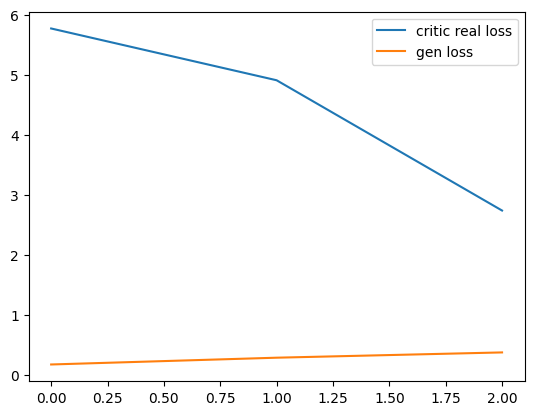

In [20]:
plt.plot(c_real_hist, label='critic real loss')
plt.plot(wgan_hist, label='gen loss')
plt.legend()
#plt.savefig('WGAN_loss_fig.png')
plt.show()

In [21]:
#Save the generator model
#generator_St37.save("WGAN_generator_St37_3Epochs.keras")

# Save the discriminator model
#critic_St37.save("critic_St37_3Epochs.keras")


<br>

## 6. Augment new data with the generator

<br>

In [27]:
generator_St37 = keras.models.load_model("WGAN-GP_generator_St37_1000Epochs.keras")

In [53]:
lat_noise = np.random.normal(0, 1, (batch_size, latent_space))
augmented_data_St37 = generator_St37.predict(lat_noise)

augmented_data_St37

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


array([[5.40701672e-02, 1.43865207e-02, 4.45484281e-01, 2.19634753e-02,
        2.20866352e-02, 1.04316743e-02, 4.96776290e-02, 1.69428214e-02,
        1.12312950e-01],
       [1.09411664e-01, 1.35274064e-02, 4.93543237e-01, 7.74611253e-03,
        3.63460183e-03, 1.15169464e-02, 2.72488017e-02, 9.59284324e-03,
        1.93617776e-01],
       [3.93185839e-02, 2.64708837e-03, 5.20494342e-01, 1.73111830e-03,
        1.14813680e-03, 7.80712639e-04, 5.22581674e-03, 1.41264172e-03,
        7.84351751e-02],
       [6.13899343e-02, 9.33039282e-03, 4.34968054e-01, 4.20888327e-03,
        4.22041910e-03, 1.57967443e-03, 1.16831679e-02, 6.90578297e-03,
        1.62995875e-01],
       [7.34733343e-02, 1.90556385e-02, 3.86667609e-01, 1.06479693e-02,
        1.22105200e-02, 1.14254262e-02, 4.03857529e-02, 8.03730357e-03,
        4.77755629e-02],
       [7.94889331e-02, 1.72629878e-02, 4.44043130e-01, 1.87645853e-02,
        1.34810153e-02, 9.92758572e-03, 4.31058928e-02, 1.33523522e-02,
        1.9

<br>

**Compare augmented data to real ones after PCA on a 3D coordinate system**

In [54]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D

In [55]:
scaler = StandardScaler()
scaled_augmented_rows = scaler.fit_transform(augmented_data_St37)
scaled_augmented_rows

array([[-3.90854269e-01, -3.56533080e-01, -1.00096799e-01,
        -3.29840839e-01, -3.14769715e-01, -3.54651093e-01,
        -2.69238293e-01, -3.26966047e-01, -3.02503914e-01],
       [-1.71635389e-01, -3.59619617e-01,  7.59773791e-01,
        -3.80340815e-01, -3.80429745e-01, -3.50979596e-01,
        -3.53093594e-01, -3.53197783e-01,  5.09927683e-02],
       [-4.49288279e-01, -3.98709565e-01,  1.24198294e+00,
        -4.01706040e-01, -3.89277607e-01, -3.87300342e-01,
        -4.35431570e-01, -3.82392555e-01, -4.49797511e-01],
       [-3.61859202e-01, -3.74698311e-01, -2.88253069e-01,
        -3.92905027e-01, -3.78345162e-01, -3.84597450e-01,
        -4.11289275e-01, -3.62787783e-01, -8.21449682e-02],
       [-3.13994378e-01, -3.39758247e-01, -1.15244436e+00,
        -3.70033413e-01, -3.49913061e-01, -3.51289213e-01,
        -3.03978086e-01, -3.58749449e-01, -5.83099186e-01],
       [-2.90165365e-01, -3.46198738e-01, -1.25881866e-01,
        -3.41203272e-01, -3.45392108e-01, -3.563564

In [56]:
pca = PCA(3)
pca_augmented_rows = pca.fit_transform(scaled_augmented_rows)
pca_augmented_rows 

array([[-9.14156497e-01,  2.18502730e-01, -3.83975240e-03],
       [-9.08963203e-01, -6.25874698e-01, -3.76751423e-01],
       [-1.31708729e+00, -1.07743084e+00,  5.15783764e-02],
       [-9.27975059e-01,  4.25055236e-01, -2.03278646e-01],
       [-8.87823641e-01,  1.26558864e+00,  1.82533100e-01],
       [-7.82059073e-01,  2.43409559e-01, -2.97713250e-01],
       [-8.29278111e-01,  1.23272240e+00, -5.01384102e-02],
       [-1.00805438e+00, -7.84194887e-01, -9.89553481e-02],
       [-8.85980129e-01, -8.97237539e-01,  4.92147505e-02],
       [-4.54095900e-01,  4.70688343e-01, -5.23443699e-01],
       [-1.07893658e+00, -1.62999034e+00, -9.51014087e-03],
       [-7.94665873e-01,  3.80711317e-01,  5.61937205e-02],
       [-6.89001381e-01,  5.48320711e-01, -2.55061388e-01],
       [-8.30069900e-01, -5.13329268e-01, -3.40931058e-01],
       [ 7.47732353e+00, -1.84650147e+00,  1.54277086e+00],
       [ 9.18546677e+00, -2.55829275e-01, -5.11092424e-01],
       [-7.91508794e-01,  1.92105985e+00

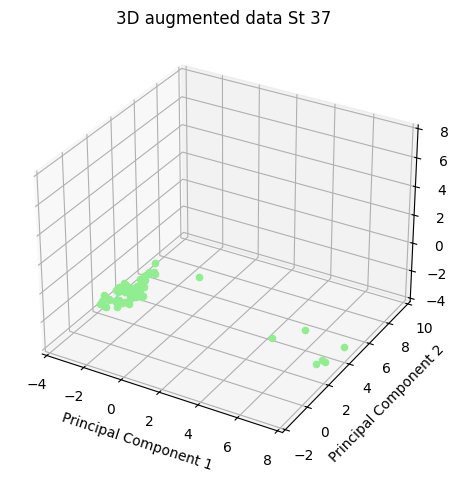

In [57]:
x = pca_augmented_rows[:, 0]
y = pca_augmented_rows[:, 1]
z = pca_augmented_rows[:, 2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c='lightgreen', marker='o')

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D augmented data St 37')

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

#plt.savefig('Aug_St37_WGAN_GP.jpg', format='jpg')

plt.tight_layout()
plt.show()

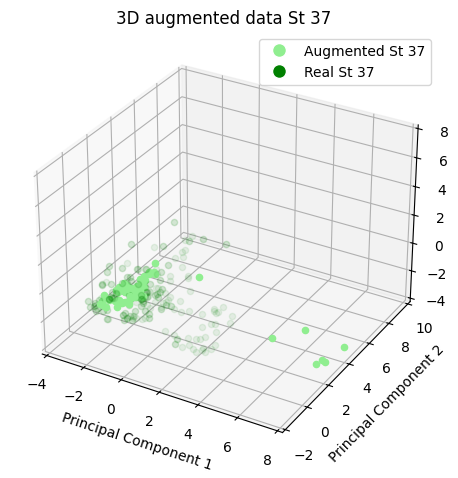

In [58]:
st37_samples = dfs_by_steeltype[1]
scaled_St37_rows = scaler.fit_transform(st37_samples)
pca_St37_rows = pca.fit_transform(scaled_St37_rows)

x_st37 = pca_St37_rows[:, 0]
y_st37 = pca_St37_rows[:, 1]
z_st37 = pca_St37_rows[:, 2]

fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')

for i in range(len(x)):
        ax.scatter(x[i], y[i], z[i], c='lightgreen', marker='o', label="Augmented St 37")

for i in range(len(x_st37)):
        ax.scatter(x_st37[i], y_st37[i], z_st37[i], c='g', marker='o', alpha=0.08, label="Real St 37")

legend_elements = []
legend_elements.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="lightgreen", markersize=10, label="Augmented St 37"))
legend_elements.append(Line2D([0], [0], marker="o", color="w", markerfacecolor="g", markersize=10, label="Real St 37"))
plt.legend(handles=legend_elements, loc="upper right")

ax.set_xlabel('Principal Component 1')
ax.set_ylabel('Principal Component 2')
ax.set_zlabel('Principal Component 3')
ax.set_title('3D augmented data St 37')

ax.set_xlim(-4, 8)
ax.set_ylim(-2, 10)
ax.set_zlim(-4, 8)

#plt.savefig('Aug_ALLSt37_WGAN_GP.jpg', format='jpg')

plt.tight_layout()
plt.show()

<br>

In [59]:
df = pd.DataFrame(augmented_data_St37, columns=['C', 'Si', 'Mn', "P", "S", "Cr", "Ni", "Al", "Cu"])

#Ranges
column_range_C = df["C"].min(), df["C"].max()
column_range_Si = df["Si"].min(), df["Si"].max()
column_range_Mn = df["Mn"].min(), df["Mn"].max()
column_range_P = df["P"].min(), df["P"].max()
column_range_S = df["S"].min(), df["S"].max()
column_range_Cr = df["Cr"].min(), df["Cr"].max()
column_range_Ni = df["Ni"].min(), df["Ni"].max()
column_range_Al = df["Al"].min(), df["Al"].max()
column_range_Cu = df["Cu"].min(), df["Cu"].max()

print("Range of C: ", column_range_C)
print("Range of Si: ", column_range_Si)
print("Range of Mn: ", column_range_Mn)
print("Range of P: ", column_range_P)
print("Range of S: ", column_range_S)
print("Range of Cr: ", column_range_Cr)
print("Range of Ni: ", column_range_Ni)
print("Range of Al: ", column_range_Al)
print("Range of Cu: ", column_range_Cu)

Range of C:  (0.0010479315, 1.0)
Range of Si:  (0.00058481534, 1.0)
Range of Mn:  (0.31776947, 0.55749166)
Range of P:  (0.0005668235, 1.0)
Range of S:  (0.00018844513, 1.0)
Range of Cr:  (0.00029850463, 1.0)
Range of Ni:  (0.00045186598, 1.0)
Range of Al:  (0.00041053043, 1.0)
Range of Cu:  (0.0132705895, 0.9999988)


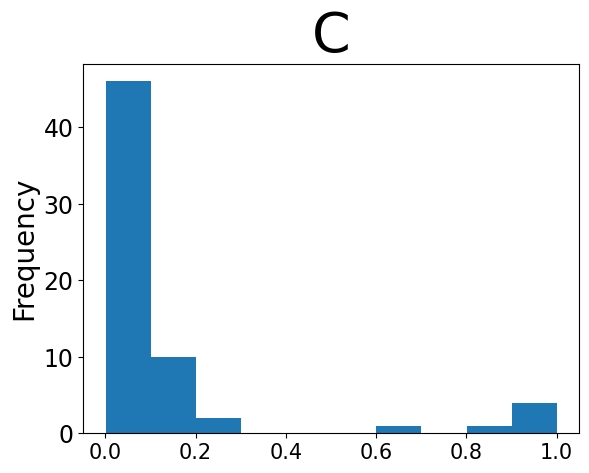

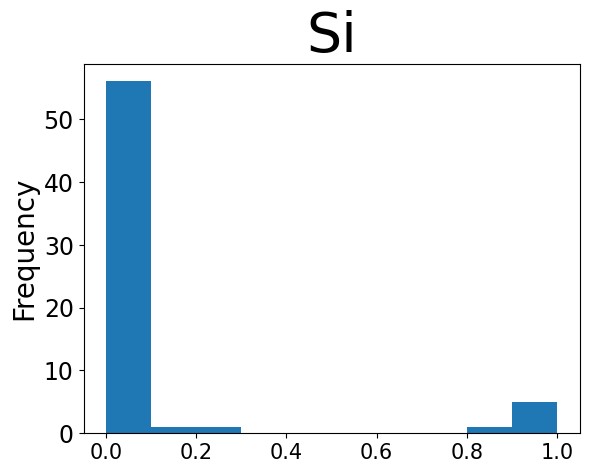

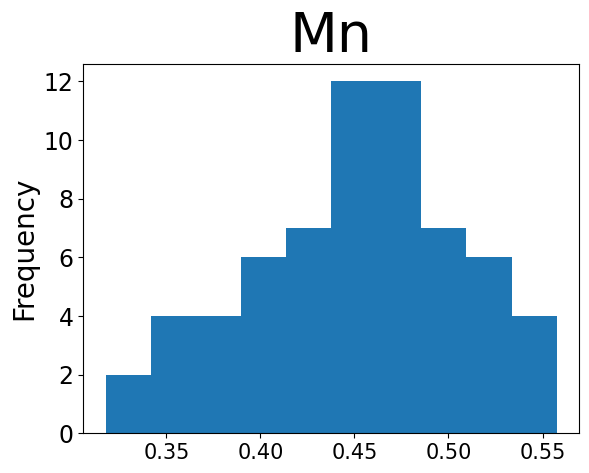

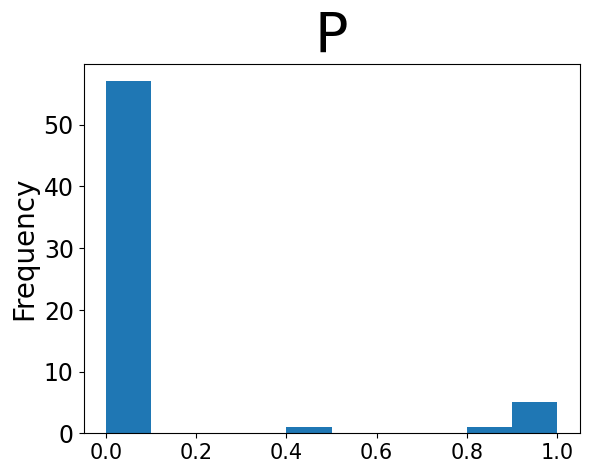

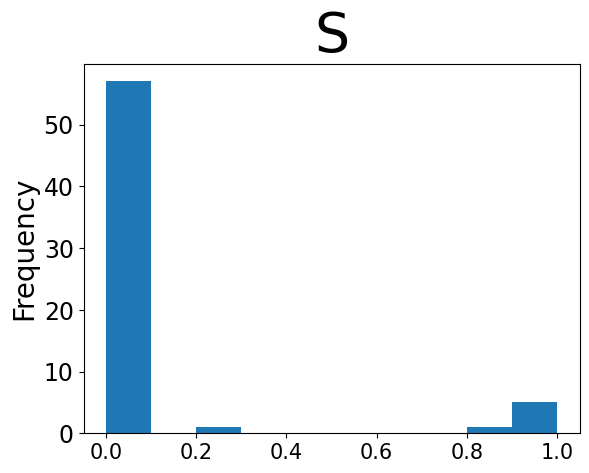

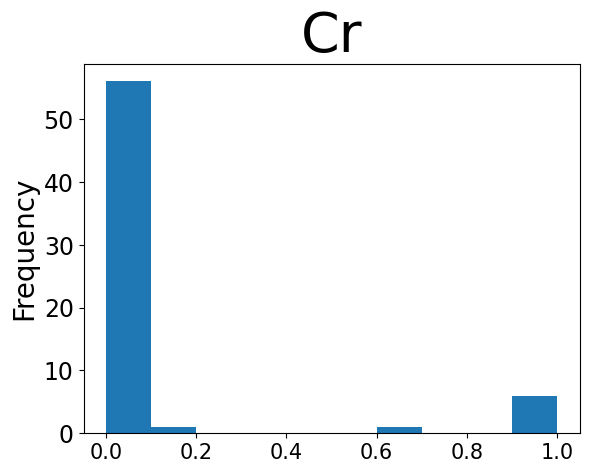

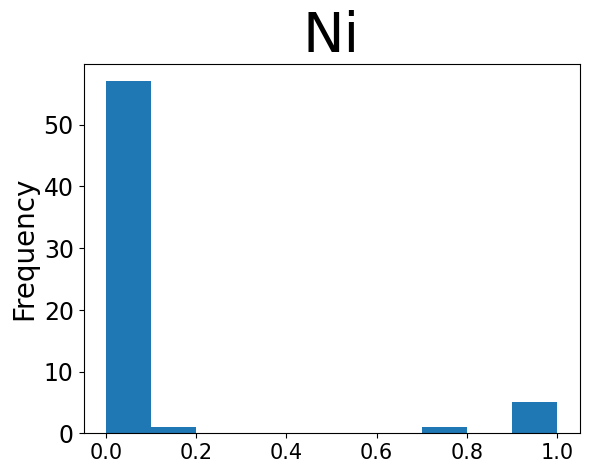

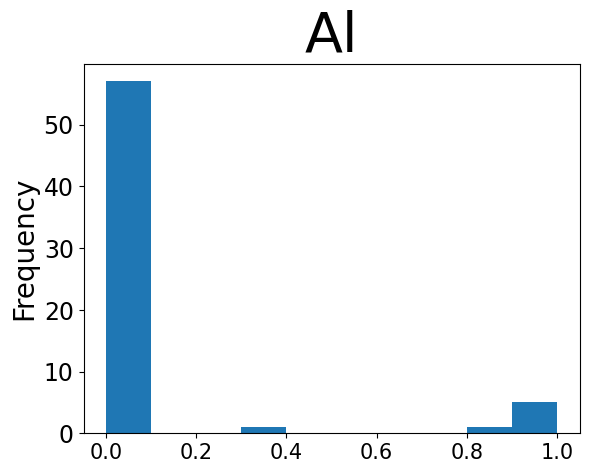

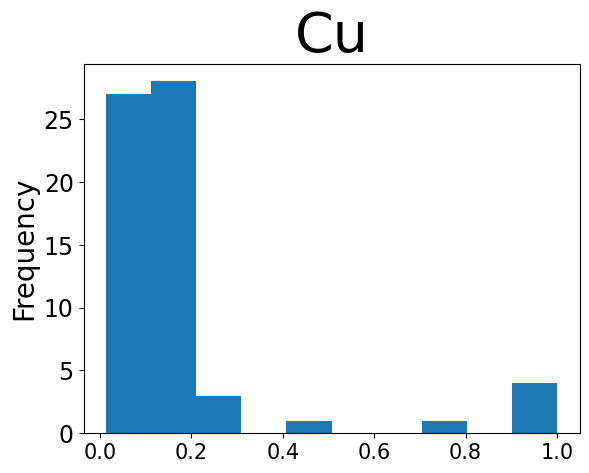

In [60]:
for col in df.columns:  # Loop through columns (excluding the first)
    df[col].plot.hist()
    plt.title(col, fontsize=40)  # Set title as element name
    plt.ylabel("Frequency", fontsize=20)
    plt.xticks(fontsize=15)  # Adjust x-axis tick label font size
    plt.yticks(fontsize=17)
    plt.savefig(f"WGAN_GP_Distribution_{col}.png", format='png')
    plt.show()
    plt.close()

## 7. Evaluate the quality of data with Steel Classification Neural Network

In [61]:
steel_classification_NN = load_model("Steel_classifiying_Neural_Network.keras")

C:\Users\jonat\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:415: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 12 variables whereas the saved optimizer has 22 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 0s/step  
64


Text(0.5, 1.0, 'Distribution of predictions of the Neural Net')

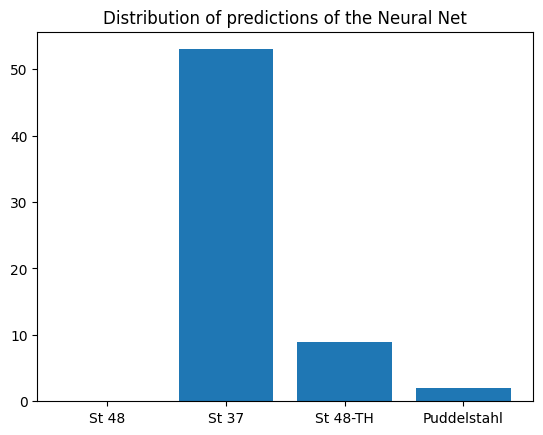

In [62]:
predictions_aug_St37 = steel_classification_NN.predict(augmented_data_St37)
rev_classes_dict = {0: "St 48", 1 : "St 37", 2 : "St Si", 3 : "St 48-TH", 4 : "Puddelstahl"}


St_37 = 0
St_48_TH = 0
Puddelstahl = 0
St_48 = 0
counter = 0
for pred in predictions_aug_St37.argmax(axis=-1):
    if rev_classes_dict[pred] == "St 37":
        St_37 += 1
    elif rev_classes_dict[pred] == "St 48-TH":
        St_48_TH += 1
    elif rev_classes_dict[pred] == "Puddelstahl":
        Puddelstahl += 1
    elif rev_classes_dict[pred] == "St 48":
        St_48 += 1
    counter += 1

print(counter)
classes = ["St 48", "St 37", "St 48-TH", "Puddelstahl"]
plt.bar(classes, [St_48, St_37, St_48_TH, Puddelstahl], align="center")
plt.title("Distribution of predictions of the Neural Net")  # Set title as element name

#plt.savefig('WGAN_GP_NN_prediction_distribution.png', format='png')

In [63]:
predictions_aug_St37.max(axis=-1)

array([0.9997391 , 0.94659066, 0.9996119 , 0.9984207 , 0.99642867,
       0.99845123, 0.9988398 , 0.9988825 , 0.60508406, 0.64756817,
       0.993404  , 0.9842688 , 0.999684  , 0.59550446, 0.9991647 ,
       0.99980205, 0.9982672 , 0.99995816, 0.58005786, 0.99989426,
       0.9998241 , 0.68645704, 0.99968016, 0.99961567, 0.99982774,
       0.9997936 , 0.9998592 , 0.997789  , 0.9637027 , 1.        ,
       0.99612254, 0.9998987 , 0.95840275, 0.99947566, 0.9997062 ,
       0.99903905, 0.99941397, 0.9998418 , 0.9998902 , 0.99994934,
       0.99279517, 0.9996232 , 0.99890006, 0.9987062 , 0.99899226,
       0.80362535, 0.99994004, 0.9999058 , 0.698663  , 0.99976426,
       0.9800403 , 0.99989855, 0.9997855 , 0.99989974, 0.99999726,
       0.9994356 , 0.9907871 , 0.6186889 , 0.9999063 , 0.9998474 ,
       0.99984896, 0.999808  , 0.9971641 , 0.78031147], dtype=float32)

<br>

<br>

## 8. Evaluate the quality of data with Steel Classification XGBoost Classifier

In [64]:
steel_classification_XGBoost = xgb.Booster()
steel_classification_XGBoost.load_model("Steel_classifying_XGBoost.json")

In [65]:
df = pd.DataFrame(augmented_data_St37, columns=["C", "Si", "Mn", "P", "S", "Cr", "Ni", "Al", "Cu"])
predictions_XGBoost = steel_classification_XGBoost.predict(xgb.DMatrix(df))

for pred in predictions_XGBoost:
    print(rev_classes_dict[pred])

St 37
Puddelstahl
St 37
St 37
Puddelstahl
Puddelstahl
St 37
St 37
St 37
St 37
St 37
St 37
St 37
Puddelstahl
St Si
St Si
Puddelstahl
St 37
St 48-TH
St 37
St Si
Puddelstahl
St Si
St 37
St Si
St 37
St 37
Puddelstahl
Puddelstahl
St 48
St 37
St 37
St 37
St 37
St 37
St 37
Puddelstahl
St 37
St 37
St 37
St 37
St 37
St 37
St 37
Puddelstahl
Puddelstahl
St 37
St 37
St 48
St 37
Puddelstahl
St 37
St 37
St 37
St 37
St 37
Puddelstahl
St 48-TH
St 37
St 37
St 37
St Si
Puddelstahl
St 37


64


Text(0.5, 1.0, 'Distribution of predictions of XGBoost')

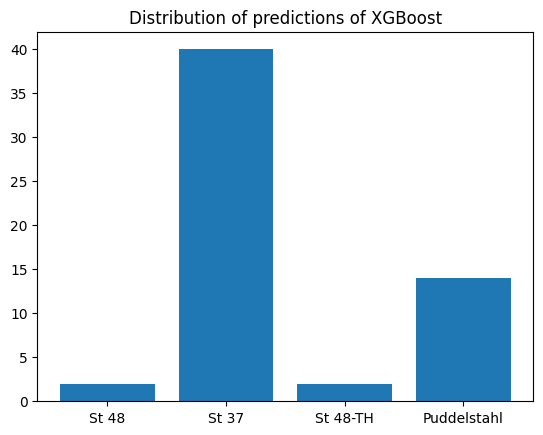

In [66]:
St_37 = 0
St_48_TH = 0
Puddelstahl = 0
St_48 = 0
counter = 0
for pred in predictions_XGBoost:
    if rev_classes_dict[pred] == "St 37":
        St_37 += 1
    elif rev_classes_dict[pred] == "St 48-TH":
        St_48_TH += 1
    elif rev_classes_dict[pred] == "Puddelstahl":
        Puddelstahl += 1
    elif rev_classes_dict[pred] == "St 48":
        St_48 += 1
    counter += 1

print(counter)
classes = ["St 48", "St 37", "St 48-TH", "Puddelstahl"]
plt.bar(classes, [St_48, St_37, St_48_TH, Puddelstahl], align="center")
plt.title("Distribution of predictions of XGBoost")  # Set title as element name

#plt.savefig('WGAN_GP_XGB_prediction_distribution.png', format='png')